# Web APIs 第五天：BOM 操作与本地存储

## 0. 本课内容与资料

本课对应 JavaScript 第 10 篇。按讲义顺序学习：`window` 与 BOM → 延时函数 → JavaScript 执行机制 → `location`、`navigator`、`history` → 本地存储 → 学生就业信息表的本地存储版本。

完成本课后，应能读取或操作浏览器地址、浏览器信息和历史记录，并让学生信息表在刷新页面后仍保留新增、删除的结果。

主资料来自[用户提供的百度网盘分享](https://pan.baidu.com/s/1MxueOHXGQtmE-ypRq1kELA?pwd=9987)，提取码 `9987`，路径为 `1. Pink最新版前端JavaScript / 2.web APIs / 资料 / web APIs第五天`。已逐页读取 `01-PPT/web APIs第五天.pdf` 全部 62 页文字层和页面图；图中的代码另作目视核对，必要教学图片裁切后内嵌于本篇。

代码使用[同课公开练习副本](https://github.com/wukaihang/pink-javascript/tree/main/2.Web%20APIs/day5)。下文注明“公开副本原代码”的代码保留原变量、缩进、换行、注释及启用状态。讲义图片转录和按讲义整理的示例分别注明来源。

网盘 `04-笔记/README.md` 的普通下载要求登录，原 Markdown 正文尚未取得；原课堂代码、Xmind 和测试题正文也未取得。`06-作业` 目录显示“没有数据”。公开副本不视为网盘原文件，讲义中已读到的作业要求保留在文末。

## 1. Window 对象

上一课主要通过 DOM 操作网页中的元素。本课通过 BOM 操作浏览器相关功能，例如等待一段时间后跳转、判断移动端浏览器、前进后退，以及保存页面数据。

### 1.1 BOM 与全局对象 window

**BOM** 是 Browser Object Model，即浏览器对象模型。在浏览器页面中，`window` 是全局对象。讲义通过下面的关系图说明 `navigator`、`location`、`document`、`history`、`screen` 与 `window` 的关系。

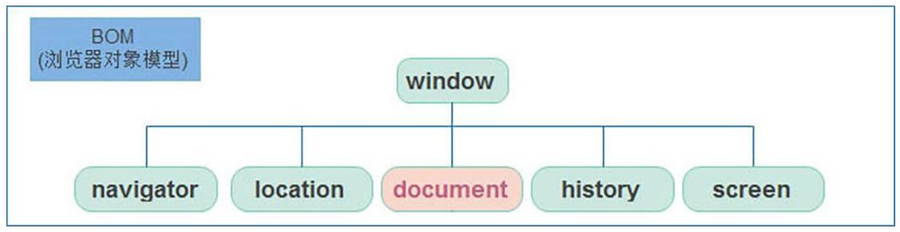

`document`、`alert()`、`console` 等可以通过 `window` 访问。例如 `window.document.querySelector()` 与 `document.querySelector()` 使用的是同一个 `document`；通常可以省略 `window`。

普通 `<script>` 的全局 `var` 声明和函数声明会成为 `window` 的属性或方法。`1-BOM.html` 公开副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // window对象是一个全局对象，也可以说是JavaScript的顶级对象
    // document、alert()、console.log()等都是window对象的属性和方法
    // 基本BOM的属性和方法都是window的
    // document.querySelector()
    // window.document.querySelector()
    console.log(window.document === document)
    // 通过var声明的变量、函数是window对象的属性、方法
    // window下的属性和方法，window可以省略
    function fn() {
      console.log('11')
    }
    window.fn()
    var num = 100
    console.log(window.num)
  </script>
</body>

</html>
```

打开页面看控制台：先输出 `true`，再通过 `window.fn()` 输出 `11`，最后通过 `window.num` 输出 `100`。

> 这里的“全局变量成为 window 属性”有范围：本例是普通脚本的全局 `var` 和函数声明。全局 `let`、`const` 不会因此成为 `window` 的同名属性，函数内部变量及模块作用域也不能套用这个结论。

### 1.2 定时器：延时函数 setTimeout

页面需要“等一段时间，只做一次操作”时使用 `setTimeout()`。它接收回调函数和等待时间，时间单位是毫秒，`1000` 毫秒是 `1` 秒。

按讲义语法整理的示例：

```javascript
const timer = setTimeout(function () {
  console.log('延迟执行')
}, 2000)

clearTimeout(timer)
```

`setTimeout()` 返回定时器 ID，交给 `clearTimeout()` 可以取消尚未执行的回调。上面紧接着取消定时器，因此不会输出“延迟执行”；需要实际观察延迟效果时，注释掉 `clearTimeout(timer)`。

公开副本 `02-延迟函数.html` 的取消语句已经处于注释状态，完整原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // 延迟两秒后执行回调函数 仅执行一次
    // 返回定时器id
    let timer = setTimeout(function () {
      console.log('11')
    }, 2000)
    // 清除定时器
    // clearTimeout(timer)
  </script>
</body>

</html>
```

打开页面约 2 秒后，控制台输出一次 `11`。等待期间，后面的同步代码会继续执行。每次调用 `setTimeout()` 都会创建新的定时器；多次设置而只保留最后一个 ID，并不会自动取消前面已经设置的定时器。

| 对比项 | `setTimeout()` 延时函数 | `setInterval()` 间歇函数 |
| --- | --- | --- |
| 回调次数 | 通常执行一次 | 周期性重复执行 |
| 典型用途 | 延迟隐藏广告、延迟操作 | 倒计时、周期性更新 |
| 取消方法 | `clearTimeout(timer)` | `clearInterval(timer)` |

> 等待时间表示回调最早具备执行条件的时间，实际执行还要等待主线程空闲。因此不能把 `2000` 理解成保证精确在第 2 秒执行。

### 1.3 案例：5 秒后隐藏广告

讲义需求是广告显示 5 秒后自动消失。实现步骤只有两步：设置延时函数，在回调中隐藏广告元素。

`03-5秒自动关闭的广告.html` 公开副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    img {
      /* fixed是相对于视口定位 */
      /* absolute是相对于最近的有定位的祖先元素定位 */
      width: 100vw;
      position: fixed;
      left: 0;
      bottom: 0;
    }
  </style>
</head>

<body>
  <img src="./images/ad.png" alt="">
  <script>
    const img = document.querySelector('img')
    let timer = setTimeout(function () {
      img.style.display = 'none'
    }, 2000)
  </script>
</body>

</html>
```

广告图片位于同目录的 `images/ad.png`。`position: fixed` 使它相对视口定位，`left: 0; bottom: 0` 把它放在左下方，`width: 100vw` 使宽度与视口一致。回调把 `display` 设为 `none`，因此广告消失。

**时间差异：**公开副本虽然文件名写“5秒”，实际参数是 `2000`，所以约 2 秒隐藏。按讲义要求练习时，把该参数改为 `5000`；上面保留公开原码。

### 1.4 JavaScript 的执行机制

讲义先给出两个“经典面试题”。下面按第 11 页代码图片转录；两个示例分别运行。

```javascript
console.log(1111)
setTimeout(function () {
  console.log(2222)
}, 1000)
console.log(3333)
// 问：输出的结果是什么？
```

```javascript
console.log(1111)
setTimeout(function () {
  console.log(2222)
}, 0)
console.log(3333)
// 问：输出的结果是什么？
```

两个示例均先输出 `1111`、`3333`，最后输出 `2222`。即使延时时间是 `0`，回调也不会插入当前同步代码中立即执行。

**单线程：**同一条 JavaScript 主线程在同一时刻只能执行一段任务。页面中的 DOM 操作需要有确定的先后顺序；如果一个任务长时间占用主线程，后续任务及页面交互会受到影响。

**同步：**按代码顺序在主线程上执行，前一步完成后再处理下一步。讲义用“烧水完成后再切菜、炒菜”作比喻。

**异步：**等待某项操作的条件满足期间，可以继续处理后面的任务；条件满足后再处理回调。讲义用“烧水时同时准备其他饭菜”作比喻。

讲义提及 Web Worker 可以创建额外工作线程。需要区分：浏览器定时器、事件等异步机制并不需要先创建 Worker；本课的回调仍在主线程上执行，不表示两段主线程 JavaScript 同时执行。

| 本课涉及的异步来源 | 例子 | 何时具备处理条件 |
| --- | --- | --- |
| 普通事件 | `click`、`resize` | 对应事件发生 |
| 资源加载 | `load`、`error` | 加载完成或发生错误 |
| 定时器 | `setTimeout`、`setInterval` | 达到等待时间 |

### 1.5 执行栈、任务队列与事件循环

**执行栈**用于执行当前 JavaScript 调用；**任务队列**保存已经具备执行条件、等待处理的任务。讲义以以下图示解释基本过程。

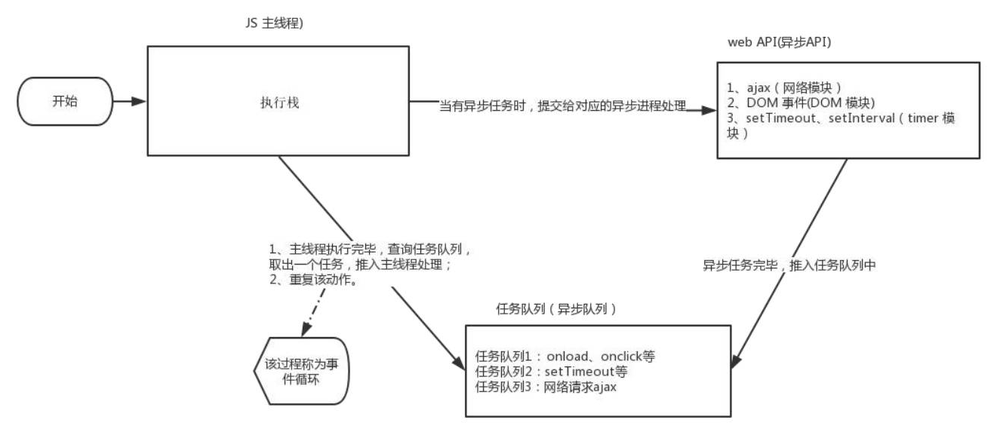

1. 先执行当前执行栈里的同步代码。
2. 遇到定时器、事件等，由浏览器处理等待或监听；达到条件后，把相应回调作为任务加入队列。
3. 当前执行栈清空后，取出排队的任务执行。
4. 不断取任务、执行任务，这个过程称为**事件循环（event loop）**。

注册事件监听本身会立即执行，但事件处理函数要等事件发生。设置定时器本身也立即执行，定时回调则等待后续调度。

第 17 页的思考题按文字和页面排版转录：

```javascript
console.log(1)
document.addEventListener('click', function () {
  console.log(4)
})
console.log(2)
setTimeout(function () {
  console.log(3)
}, 3000)
```

不点击时，先输出 `1`、`2`，约 3 秒后输出 `3`；点击时还会输出 `4`，它与 `3` 的顺序取决于点击发生的时间。

`04-时间循环.html` 公开副本加了同步输出 `4`，把点击输出改为 `5`。完整原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // 同步任务直接放入执行栈中执行
    console.log(1)
    // 异步任务（定时器、点击事件、网络请求Ajax）执行完后，会将回调函数放入任务队列中
    // 任务队列中的任务依次放入执行栈中执行
    document.addEventListener('click', function () {
      console.log(5)
    })
    console.log(2)
    setTimeout(function () {
      console.log(3)
    }, 3000)
    console.log(4)
  </script>
</body>

</html>
```

这个版本不点击时输出 `1 → 2 → 4 → 3`；点击时输出 `5`。不要把两个版本的数字对应关系混在一起。

> 图示是本课用于解释定时器与事件的基础模型。这里的“按次序”指按任务排队和浏览器调度处理，并非按异步函数在源码里出现的先后执行。

### 1.6 location：地址的读取、跳转和刷新

`location` 是对象，保存当前 URL 的各个组成部分。讲义重点是以下属性和方法：

| 属性或方法 | 作用 | 示例与边界 |
| --- | --- | --- |
| `location.href` | 获取完整 URL；赋值后跳转 | `location.href = 'http://www.itcast.cn'` |
| `location.search` | 获取查询参数部分 | 返回值包含开头的 `?`；没有查询参数时是空字符串 |
| `location.hash` | 获取片段部分，即哈希值 | 返回值包含开头的 `#`；没有片段时是空字符串 |
| `location.reload()` | 重新加载当前页面 | 类似浏览器刷新 |

例如当前地址为 `https://example.com/index.html?uname=pink#cart` 时，`search` 是 `?uname=pink`，`hash` 是 `#cart`。

讲义使用哈希值为后续路由学习作铺垫：通过 `#` 后的内容区分不同页面状态，常见于不重新加载整个页面的界面切换。单纯改变哈希值不会自动生成对应界面，还需要程序处理它。

`05-location对象.html` 公开副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <form action="">
    <input type="text" name="username">
    <input type="password" name="password">
    <button type="submit">登录</button>
  </form>
  <a href="#/my">我的</a>
  <a href="#/cart">购物车</a>
  <a href="#/home">首页</a>

  <button class="reload">重新加载</button>
  <script>
    console.log(location)
    // 1. location.href 可以获取当前页面的url地址
    console.log(location.href)
    // location.href = 'https://www.baidu.com'
    // 2. location.search 可以获取url地址中的查询参数部分
    console.log(location.search)
    // 3. location.hash 可以获取url地址中的哈希值部分

    // 4. reload 可以重新加载当前页面
    const reload = document.querySelector('.reload')
    reload.addEventListener('click', function () {
      // 类似按F5键重新加载页面
      location.reload()
      // 类似按Ctrl+F5重新加载页面
      // location.reload(true)
    })
  </script>
</body>

</html>
```

在页面中点击“我的”“购物车”“首页”，地址末尾分别变为 `#/my`、`#/cart`、`#/home`。原代码没有执行 `console.log(location.hash)`，要观察当前值可以在控制台直接读取 `location.hash`。

表单里的 `name="username"`、`name="password"` 让提交后的 URL 查询字符串包含相应字段，这是观察 `search` 的课堂练习；使用虚构数据即可。重新加载按钮调用 `location.reload()`，重新运行页面脚本。

> 讲义把 `location.reload(true)` 解释为强制刷新，公开副本也保留了这一行注释。`true` 参数不属于标准 `reload()` 用法，当前 Chromium 浏览器不会保证因此绕过缓存；本例实际启用的是 `location.reload()`。需要观察强制刷新时使用浏览器提供的刷新操作。

### 1.7 案例：5 秒后自动跳转

需求是用户可以直接点击链接跳转；如果不点击，页面显示秒数倒计时，5 秒后自动跳转。

1. 用 `<a>` 提供可点击的目标地址。
2. 初始化剩余秒数 `num = 5`。
3. 每秒减少 `num` 并更新提示。
4. `num <= 0` 时清除间歇定时器，再给 `location.href` 赋值。

`06-5秒之后自动跳转页面.html` 公开副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <a href="http://www.itcast.cn">支付成功<span>5</span>秒之后自动跳转到首页</a>
  <script>
    const a = document.querySelector('a')
    let num = 5
    let timer = setInterval(function () {
      num--
      a.innerHTML = `支付成功<span>${num}</span>秒之后自动跳转到首页`
      if (num <= 0) {
        clearInterval(timer)
        location.href = 'http://www.itcast.cn'
      }
    }, 1000);
  </script>
</body>

</html>
```

正常观察时，提示从 `5` 变为 `4、3、2、1、0`，随后跳转。这里需要重复更新倒计时，所以使用 `setInterval()`；只写一个 `setTimeout()` 可以延迟跳转，却不会自行每秒更新显示。

### 1.8 navigator：浏览器信息与移动端跳转

`navigator` 记录浏览器自身的相关信息。本课读取 `navigator.userAgent`，用字符串匹配判断 Android 或 iPhone；匹配后跳转到移动站点。

`07-自动跳转到移动端.html` 公开副本原代码：

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <script>
    // 检测 userAgent（浏览器信息）
    !(function () {
      const userAgent = navigator.userAgent
      // 验证是否为Android或iPhone
      const android = userAgent.match(/(Android);?[\s\/]+([\d.]+)?/)
      const iphone = userAgent.match(/(iPhone\sOS)\s([\d_]+)/)
      // 如果是Android或iPhone，则跳转至移动站点
      if (android || iphone) {
        location.href = 'https://m.weibo.cn/'
      }
    })();
    // !(function () { })(); 
    // !function () { }()  //匿名函数 等价于 (function () { })()
  </script>
</head>

<body>
  这是pc端的页面
  <script>
    // (function () { })()
  </script>
</body>

</html>
```

`match()` 匹配成功时返回结果，失败时返回 `null`。`android || iphone` 有匹配结果时，就执行跳转。立即执行函数让页面加载时执行一次检测；外面的 `!` 是该写法中把函数当作表达式的一种方式。

讲义跳转目标为 `http://m.itcast.cn`，公开副本目标为 `https://m.weibo.cn/`，上面保留公开副本地址。桌面浏览器通常保留“这是pc端的页面”；模拟对应手机 User-Agent 时进入跳转分支。

> User-Agent 是浏览器提供的字符串，可以变化或被修改。这个例子用于演示平台检测与跳转，不能据此保证识别所有移动设备；本课也没有处理 iPad 等其他设备。

### 1.9 history：前进与后退

`history` 管理当前浏览上下文的会话历史。讲义方法表中的拼写应为 `history`，部分小标题误写为 `histroy`。

| 方法 | 作用 |
| --- | --- |
| `history.back()` | 后退一步 |
| `history.forward()` | 前进一步 |
| `history.go(-1)` | 后退一步 |
| `history.go(1)` | 前进一步 |
| `history.go(n)` | 相对当前记录移动 `n` 步，正数前进、负数后退 |

`08-history对象.html` 公开副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <button>后退</button>
  <button>前进</button>
  <script>
    const back = document.querySelector('button:first-child')
    const forward = back.nextElementSibling
    back.addEventListener('click', function () {
      // 后退一步
      // history.back()
      history.go(-1)
    })
    forward.addEventListener('click', function () {
      // 前进一步
      // history.forward()
      history.go(1)
    })
  </script>
</body>

</html>
```

原例启用的是 `go(-1)` 和 `go(1)`，`back()`、`forward()` 保留在注释中。验证时先在同一标签页产生前后历史记录，再回到本页面操作；缺少可用记录时，按钮不会凭空打开一个页面。讲义提到这类功能可见于 OA 办公系统。

## 2. 本地存储

上一课的学生表只在数组中保存数据，刷新时脚本重新运行，数组便回到初始状态。要让刷新后仍能恢复数据，需要在浏览器中保存数据，并在下一次加载时读取。

### 2.1 本地存储的用途与分类

讲义介绍 HTML5 提供的 `localStorage` 和 `sessionStorage`：数据保存在用户浏览器中，以键值对方式设置和读取，刷新页面后可以继续读取。

讲义以 TodoMVC 的待办事项为例：刷新后仍能显示已有项目。这种体验需要把数据保存下来，再恢复到页面。

| 对比项 | `localStorage` | `sessionStorage` |
| --- | --- | --- |
| 保存周期 | 关闭页面后通常仍保留，直到主动删除或被清理 | 当前标签页或窗口的页面会话内保留 |
| 刷新页面 | 通常保留 | 当前会话内保留 |
| 共享范围 | 同源页面可共享 | 同源且同一标签页的页面可共享 |
| 数据形式 | 键值对，值保存为字符串 | 键值对，值保存为字符串 |
| 操作方法 | `setItem`、`getItem`、`removeItem` | 同样的方法 |

讲义给出的容量印象是约 `5M`；实际额度由浏览器等因素决定。多页面共享还有**同源**条件，即协议、主机和端口相同；同一个浏览器中不同站点不会因此共享全部存储数据。

“永久存储”在本课指不随普通关闭页面而消失，并非永远不会丢失。浏览器清理、隐私模式等会影响保存。练习时保持同一页面地址和浏览器环境，避免换了来源后误以为数据没有保存。

### 2.2 localStorage：存储、读取、修改与删除

| 操作 | 语法 | 结果 |
| --- | --- | --- |
| 存储 | `localStorage.setItem(key, value)` | 保存键和值 |
| 读取 | `localStorage.getItem(key)` | 返回字符串；键不存在时返回 `null` |
| 修改 | 再次 `setItem` 同一个键 | 用新值覆盖旧值 |
| 删除 | `localStorage.removeItem(key)` | 删除指定键 |

`09-localStorage存储.html` 公开副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    // 1. 要存储一个名字
    // localStorage.setItem('key', 'value') 键值对形式
    localStorage.setItem('name', 'wukaihang')
    // 2. 获取
    // localStorage.getItem('key')
    const name = localStorage.getItem('name')
    console.log(name)
    // 4. 修改
    // 直接setItem即可
    localStorage.setItem('name', 'wukaihang123')
    console.log(localStorage.getItem('name'))
    // 3. 删除
    // localStorage.removeItem('key')
    localStorage.removeItem('name')
    console.log(localStorage.getItem('name'))

    // 本地存储只能存储字符串
    localStorage.setItem('age', 18)
    console.log(typeof localStorage.getItem('age'))
  </script>
</body>

</html>
```

按顺序执行后，控制台依次显示 `wukaihang`、`wukaihang123`、`null`、`string`。名字已经被删除，但 `age` 仍然保存。即使写入的是数字 `18`，读取时得到的也是字符串 `'18'`。

在浏览器开发者工具中进入 **Application（应用）→ Local Storage（本地存储）→ 当前来源**，检查 `Key`、`Value`。讲义截图中的 `uname / andy` 是展示用数据；运行上述公开代码后应查看 `age / 18`。

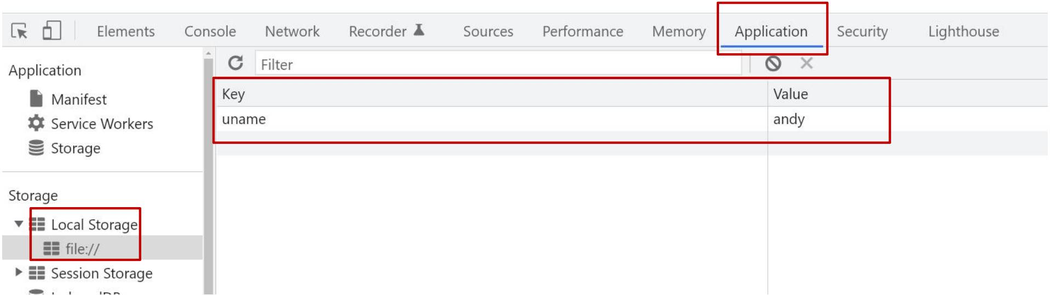

如果刷新这个练习页面，脚本会再次执行设置、修改和删除；观察它时应区分“已有值被浏览器保存”和“页面脚本再次写入值”。

### 2.3 sessionStorage：页面会话内保存

`sessionStorage` 的基本方法与 `localStorage` 相同。下面是按讲义方法整理的独立示例：

```javascript
sessionStorage.setItem('uname', 'pink')
console.log(sessionStorage.getItem('uname'))
sessionStorage.setItem('uname', 'red')
sessionStorage.removeItem('uname')
```

要观察刷新后保留，可先只执行存储语句，然后刷新同一标签页并读取。关闭该标签页或窗口会结束这次页面会话；不能把它与 `localStorage` 的长期保留混用。

本课最终要求学生信息刷新后保留，并使用 `localStorage` 完成综合案例。

### 2.4 复杂数据：JSON.stringify 与 JSON.parse

学生信息是一组对象。直接把普通对象传给 `setItem()`，浏览器会进行字符串转换，通常得到 `'[object Object]'`，这个值无法保留对象的字段结构。

因此保存前把数组或对象转成 **JSON 字符串**，读取后再还原：

| 阶段 | 操作 | 得到什么 |
| --- | --- | --- |
| 保存前 | `JSON.stringify(对象或数组)` | 描述数据结构的 JSON 字符串 |
| 保存 | `localStorage.setItem(key, JSON字符串)` | 字符串写入本地存储 |
| 读取 | `localStorage.getItem(key)` | 字符串或 `null` |
| 还原 | `JSON.parse(JSON字符串)` | 普通对象或数组 |

`10-本地存储复杂数据类型.html` 公开副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    const obj = {
      name: 'wukaihang',
      age: 18,
      gender: '男'
    }
    // 存储对象时，需要将对象转换为字符串
    // JSON对象 属性和值都要加 双引号
    localStorage.setItem('obj', JSON.stringify(obj))
    // 获取对象
    const objStr = localStorage.getItem('obj')
    // console.log(objStr)
    // console.log(typeof objStr)
    console.log(JSON.parse(objStr))

  </script>
</body>

</html>
```

存储中的值是 `{"name":"wukaihang","age":18,"gender":"男"}`，读取成 `objStr` 后仍是字符串。`JSON.parse(objStr)` 返回对象，才能通过属性访问姓名、年龄等字段。

> 原注释“属性和值都要加双引号”需要区分值的类型：JSON 的属性名和字符串值使用双引号，数字、布尔值、`null` 不加双引号。上面的 `age` 是数字 `18`。使用 `JSON.stringify()` 可以正确处理这些格式。

保存与读取的转换方向不要写反：`stringify` 是数据转字符串，`parse` 是字符串转数据。手工改坏的 JSON 字符串会让 `JSON.parse()` 抛错；后面的课堂案例默认存储内容是合法的学生数组。

## 3. 综合案例：学生就业信息表

本课在上一天学生表的基础上加入本地存储。用户录入学生后刷新，数据仍显示；删除后刷新，已删除的学生不再恢复。

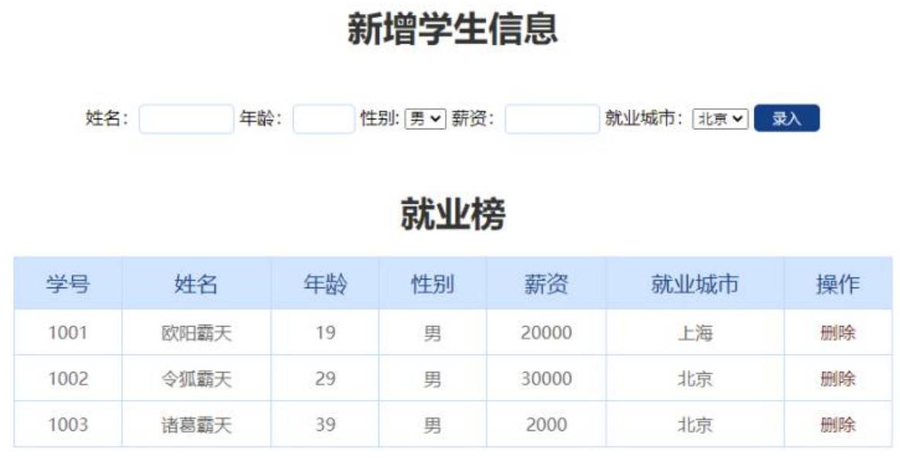

### 3.1 业务划分与实现顺序

讲义先划分新增、渲染、删除三个模块，再按实际加载顺序展开：

1. **读取：**先查本地存储；有数据就转成数组，没有就使用空数组。
2. **渲染：**根据当前数组生成表格。
3. **新增：**验证表单、把数据追加到数组、更新本地存储、重新渲染、重置表单。
4. **删除：**找出数组中的对应项、删除、更新本地存储、重新渲染。

数组负责当前页面的数据，本地存储负责下次打开或刷新后的恢复，表格只是这些数据的展示。只改页面行而不改数组和存储，刷新后就会恢复旧数据。

公开副本的目标文件是 `学生信息表/学生信息表案例.html`，样式文件为同目录 `css/index.css`。整份原代码放在本章后面，以下按讲义解释每一步。

### 3.2 第一步：读取已有数据

公开副本使用的核心表达式：

```javascript
const arr = JSON.parse(localStorage.getItem('data')) || []
```

键 `data` 已存在且保存合法学生数组时，解析得到这个数组；键不存在时，`getItem()` 返回 `null`，`JSON.parse(null)` 得到 `null`，`|| []` 提供空数组。

读取之后调用 `render()`，不能在每次加载时都把初始数据写回去，否则已有学生就会被覆盖。公开副本保留了一组注释掉的 `initData` 和写入语句；它们适合初次演示，默认不执行。

`const arr` 固定的是变量的引用，仍可以对数组执行 `push()`、`splice()`。本例始终操作同一个数组。

> `|| []` 只能提供空值回退，不能捕获 JSON 解析错误，也不能证明已有值是数组。原案例假定当前来源下 `data` 保存的是合法数组；调试时若手动改坏该键，需要先检查和恢复数据，不能以为这个表达式会自动修复任何内容。

### 3.3 第二步的准备：map 与 join

上一课循环创建 `<tr>` 并追加节点；本课先把每条记录变成一段表格 HTML，再一次赋给 `tbody.innerHTML`，减少逐条插入 DOM 的操作。

**`map()`：**遍历数组，对每个元素执行回调，把每次回调的返回值组成新数组。回调的第一个参数是当前元素，第二个参数是索引。讲义称这种一一对应关系为“映射”。

**`join()`：**把数组元素连接成字符串，参数指定连接符；不传参数时默认使用逗号。

`10-map方法和join方法.html` 公开副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <script>
    const arr = ['red', 'green', 'blue']
    // 1. 数组map方法
    // map 方法用于遍历数组，将数组中的每个元素进行处理，返回一个新数组
    // forEach 方法用于遍历数组，将数组中的每个元素进行处理，没有返回值
    const newArr = arr.map(function (ele, index) {
      console.log(ele, index) // 数组元素和索引号 red 0
      return ele + '颜色'
    })
    console.log(newArr)

    // 2. 数组join方法
    // join 方法用于将数组中的元素连接起来，返回一个字符串
    // 参数：指定连接符，默认是逗号
    const str = newArr.join('|')
    console.log(str)
  </script>
</body>

</html>
```

这个例子得到新数组 `['red颜色', 'green颜色', 'blue颜色']`，再通过 `join('|')` 得到 `red颜色|green颜色|blue颜色`。原数组仍是 `['red', 'green', 'blue']`；本例回调没有修改原元素。

| 方法 | 本课重点 | 回调返回值是否组成新数组 |
| --- | --- | --- |
| `forEach()` | 遍历执行操作 | 否，方法返回 `undefined` |
| `map()` | 把每个学生对象转成一段 `<tr>` 字符串 | 是，需要写 `return` |
| `join('')` | 把字符串数组拼成一段 HTML | 方法直接返回字符串 |

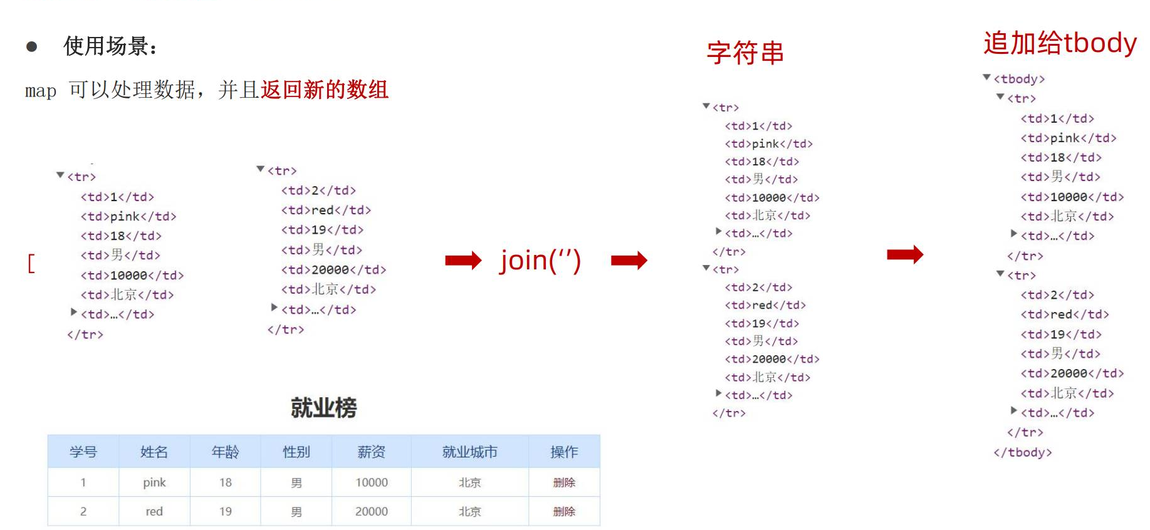

> 表格拼接使用 `join('')`，连接符是空字符串。如果省略参数，元素之间会多出逗号；如果 `map()` 回调忘记 `return`，新数组里就不是需要的表格字符串。

### 3.4 渲染：把学生数组写到 tbody

`render()` 中使用 `arr.map(function (ele, index) { ... })`。每个 `ele` 是一条学生数据，模板字符串中的 `${ele.uname}` 等表达式读取对应字段。

一条记录对应一个 `<tr>`，列依次为学号、姓名、年龄、性别、薪资、就业城市和删除链接。`map()` 得到字符串数组，再通过 `trArr.join('')` 拼接，最后写入 `tbody.innerHTML`。

删除链接带 `data-id="${index}"`，这里保存的是**当前数组索引**；`ele.stuId` 是展示的**学号**。两者用途不同，不能把学号直接交给 `splice()` 当索引。

每次重新渲染都会重建这些链接，并重新生成当前索引。因此在前面删除一项后，后面记录的索引随数组变化，但原有学号不必变化。

公开副本先写 `tbody.innerHTML = ''`，随后又直接赋值整个新字符串。后一次赋值本身就会覆盖旧内容，前面的清空并非必需；原代码保留。

### 3.5 录入：阻止提交、验证并保存

讲义以 `form` 的 `submit` 事件处理录入。`e.preventDefault()` 阻止默认提交，避免还没处理完数据就导航或刷新。

讲义第 56～58 页给出的步骤：

1. 取得需要填写的表单控件，它们带有 `name` 属性。
2. 遍历检查值是否为空；有一项为空就提示并 `return`。
3. 创建学生对象，先生成 `stuId`，再利用控件的 `name` 把值赋给对象的同名属性。
4. 将对象追加到数组。
5. 使用 `JSON.stringify(arr)` 更新本地存储。
6. 调用渲染函数。
7. 重置表单。

下面是**按讲义循环收集字段的思路整理**的监听器，供替换公开副本的新增监听器使用。前提是该页面已有 `info`、`arr`、`render()`，控件的 `name` 分别为 `uname`、`age`、`gender`、`salary`、`city`；它不是网盘原代码的逐字摘录。

```javascript
const items = info.querySelectorAll('[name]')

info.addEventListener('submit', function (e) {
  e.preventDefault()
  const obj = {
    stuId: arr.length ? arr[arr.length - 1].stuId + 1 : 1
  }

  for (let i = 0; i < items.length; i++) {
    if (!items[i].value.trim()) {
      alert('请填写完整信息')
      return
    }
    obj[items[i].name] = items[i].value.trim()
  }

  arr.push(obj)
  localStorage.setItem('data', JSON.stringify(arr))
  render()
  info.reset()
})
```

方括号 `obj[items[i].name]` 使用控件的 `name` 作为属性名。例如 `name="uname"` 的控件会写到 `obj.uname`。`return` 退出提交回调；即使临时对象已收集了部分字段，未通过验证时也没有执行 `arr.push()`，因此不会新增半条记录。

**与公开副本的差异：**公开原码直接检查 `uname`、`age`、`salary` 并分别取值，还记录 `time`；没有 `.trim()`，只含空格的输入可以通过其非空检查。整理示例按讲义循环收集的主线，同时把纯空白视为空，并未替换后面的完整公开原码。

### 3.6 学号：最后一条的 stuId 加 1

讲义第 60 页强调：新学号不能简单用 `arr.length + 1`，因为删除中间记录后，数组长度并不等于最后一个学号。

核心表达式：

```javascript
stuId: arr.length ? arr[arr.length - 1].stuId + 1 : 1
```

有记录时取最后一个对象的学号加 `1`；空数组时从 `1` 开始。讲义初始展示图的学号为 `1001` 等，但其空数组处理明确从 `1` 开始，公开副本也采用这个规则。

例如已有学号 `1、2、3`，删除学号 `2` 后数组是 `1、3`，下一次新增应为 `4`；使用数组长度加 `1` 就会再次生成 `3`。

> 该课堂规则假定现有记录按追加顺序保存、学号是数字。删除最后一项再新增时可能复用刚删除的学号；全部删除后会从 `1` 重新开始。它解决当前列表中的编号问题，不保证历史上用过的编号永不重复。

### 3.7 删除：改数组，再同步存储与页面

讲义采用事件委托：把一次点击监听注册在 `tbody` 上，通过 `e.target` 判断是否点击了删除链接，避免每次重新渲染都为每个链接再次注册监听。

1. `e.target.tagName === 'A'` 时处理链接点击。
2. 读取 `e.target.dataset.id`，得到渲染时保存的数组索引。
3. 用 `arr.splice(索引, 1)` 删除对应学生。
4. 将新数组转为 JSON 字符串，更新 `data`。
5. 重新渲染表格。

公开副本还弹出 `confirm('确认删除吗？')`，取消就 `return`。`dataset.id` 是字符串，`splice()` 在这里会把它转换为索引使用。

讲义顺序是先更新存储再渲染；公开副本新增和删除中是先渲染后写入存储。在存储成功的正常课堂条件下，两者得到相同的最终页面与存储结果；上面完整原码保留公开副本顺序。

### 3.8 公开副本完整代码与样式

保存 `学生信息表案例.html`，并在它旁边建立 `css/index.css`。HTML 中的 `href="css/index.css"` 与这个目录关系对应。下面是公开副本完整 HTML 原码，包括注释掉的初始化数据；不要把其初始化写入语句无条件启用在每次加载过程中。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8" />
  <meta name="viewport" content="width=device-width, initial-scale=1.0" />
  <meta http-equiv="X-UA-Compatible" content="ie=edge" />
  <title>学生信息管理</title>
  <link rel="stylesheet" href="css/index.css" />
</head>

<body>
  <h1>新增学员</h1>
  <form class="info" autocomplete="off">
    姓名：<input type="text" class="uname" name="uname" />
    年龄：<input type="text" class="age" name="age" />
    性别:
    <select name="gender" class="gender">
      <option value="男">男</option>
      <option value="女">女</option>
    </select>
    薪资：<input type="text" class="salary" name="salary" />
    就业城市：<select name="city" class="city">
      <option value="北京">北京</option>
      <option value="上海">上海</option>
      <option value="广州">广州</option>
      <option value="深圳">深圳</option>
      <option value="曹县">曹县</option>
    </select>
    <button class="add">录入</button>
  </form>

  <h1>就业榜</h1>
  <table>
    <thead>
      <tr>
        <th>学号</th>
        <th>姓名</th>
        <th>年龄</th>
        <th>性别</th>
        <th>薪资</th>
        <th>就业城市</th>
        <th>操作</th>
      </tr>
    </thead>
    <tbody>
      <!-- 
        <tr>
          <td>1001</td>
          <td>欧阳霸天</td>
          <td>19</td>
          <td>男</td>
          <td>15000</td>
          <td>上海</td>
          <td>
            <a href="javascript:">删除</a>
          </td>
        </tr> 
        -->
    </tbody>
  </table>
  <script>
    // 1.3 获取tbody元素
    const tbody = document.querySelector('tbody')

    // // 参考数据
    // const initData = [
    //   {
    //     stuId: 1,
    //     uname: '欧阳霸天',
    //     age: 19,
    //     gender: '男',
    //     salary: '20000',
    //     city: '上海',
    //     time: '2023-08-01 10:00:00'
    //   }
    // ]
    // localStorage.setItem('data', JSON.stringify(initData))

    // 1. 渲染业务
    // 1.1 先读取本地存储的数据
    // (1) 本地存储有数据则 转换为对象后 存储到变量里面，后期用于渲染页面
    // (2) 本地存储无数据则 存储空数组
    const arr = JSON.parse(localStorage.getItem('data')) || []
    console.log(arr.length)

    // 1.2 调用渲染函数
    render()

    // 利用 map 和 join 方法 渲染页面
    function render() {
      tbody.innerHTML = ''
      // (1) 利用map遍历数组，返回对应tr的数组
      const trArr = arr.map(function (ele, index) {
        return `
          <tr>
            <td>${ele.stuId}</td>
            <td>${ele.uname}</td>
            <td>${ele.age}</td>
            <td>${ele.gender}</td>
            <td>${ele.salary}</td>
            <td>${ele.city}</td>
            <td>
              <a href="javascript:" data-id="${index}">删除</a>
            </td>
          </tr>
        `
      })
      // (2) 利用join方法将数组转换为字符串，指定连接符为空字符串
      tbody.innerHTML = trArr.join('')
    }

    // 2. 新增业务
    const info = document.querySelector('.info')
    const uname = document.querySelector('.uname')
    const age = document.querySelector('.age')
    const salary = document.querySelector('.salary')
    const gender = document.querySelector('.gender')
    const city = document.querySelector('.city')

    info.addEventListener('submit', function (e) {
      e.preventDefault()
      // 2.1 非空判断
      if (!uname.value || !age.value || !salary.value) {
        alert('请填写完整信息')
        return
      }
      // 2.2 收集表单信息
      arr.push({
        stuId: arr.length ? arr[arr.length - 1].stuId + 1 : 1,
        uname: uname.value,
        age: age.value,
        gender: gender.value,
        salary: salary.value,
        city: city.value,
        time: new Date().toLocaleString()
      })
      // 2.3 调用渲染函数
      render()
      // 2.4 清空表单
      info.reset()
      // 2.5 本地存储数据更新
      localStorage.setItem('data', JSON.stringify(arr))
    })

    // 3. 删除业务
    // 3.1 事件委托给 tbody
    tbody.addEventListener('click', function (e) {
      // 3.1.1 判断是否点击了删除
      if (e.target.tagName === 'A') {
        if (!confirm('确认删除吗？')) {
          return
        }
        // 3.1.2 删除数组中对应的元素 通过自定义属性 data-id
        arr.splice(e.target.dataset.id, 1)
        // 3.1.3 重新渲染页面
        render()
        // 3.1.4 本地存储数据更新
        localStorage.setItem('data', JSON.stringify(arr))
      }
    })
  </script>
</body>

</html>
```

对应的 `css/index.css` 公开副本原代码：

```css
* {
  margin: 0;
  padding: 0;
}

a {
  text-decoration: none;
  color:#721c24;
}
h1 {
  text-align: center;
  color:#333;
  margin: 20px 0;
 
}
table {
  margin:0 auto;
  width: 800px;
  border-collapse: collapse;
  color:#004085;
}
th {
  padding: 10px;
  background: #cfe5ff;
  
  font-size: 20px;
  font-weight: 400;
}
td,th {
  border:1px solid #b8daff;
}
td {
  padding:10px;
  color:#666;
  text-align: center;
  font-size: 16px;
}
tbody tr {
  background: #fff;
}
tbody tr:hover {
  background: #e1ecf8;
}
.info {
  width: 900px;
  margin: 50px auto;
  text-align: center;
}
.info  input, .info select {
  width: 80px;
  height: 27px;
  outline: none;
  border-radius: 5px;
  border:1px solid #b8daff;
  padding-left: 5px;
  box-sizing: border-box;
  margin-right: 15px;
}
.info button {
  width: 60px;
  height: 27px;
  background-color: #004085;
  outline: none;
  border: 0;
  color: #fff;
  cursor: pointer;
  border-radius: 5px;
}
.info .age {
  width: 50px;
}
```

### 3.9 运行检查与原例边界

在同一个浏览器、同一个来源打开学生页面，按以下顺序观察：

1. 首次打开且 `data` 不存在时，表格为空；页面没有自动写入那组注释掉的参考学生。
2. 缺少姓名、年龄或薪资时点击“录入”，收到“请填写完整信息”，表格没有增加一行。
3. 填写完整后录入，表格增加学生，表单恢复默认值，Local Storage 中的 `data` 是 JSON 数组。
4. 刷新页面，刚录入的学生仍显示。
5. 再录入学生，删除其中一项；取消确认时数据不变，确认后表格与 `data` 均减少一项。
6. 再次刷新，已确认删除的学生不再显示。
7. 删除中间记录后再新增，观察学号按最后一条递增；删除全部记录后刷新，再新增从 `1` 开始。

原例有几处需要按代码理解：

- 年龄、薪资通过 `.value` 取得，保存的是字符串；原例只做非空判断，没有校验数字范围。
- `time` 保存了 `new Date().toLocaleString()`，但原 HTML 表头及渲染模板没有时间列，因此页面不显示它。
- `innerHTML` 会把模板中的内容解析成 HTML。课堂例子直接插入表单内容；练习输入普通文本。若要接收任意文本，不能把未经处理的输入当作可信 HTML，应在输出位置使用文本节点或进行必要转义。
- 本课实现的是本地学生数组的持久化，没有跨电脑的数据同步。修改数组后需调用 `setItem()`；改了数组不会自动更新已保存的字符串。

## 4. 今日作业

讲义第 61 页要求：

1. 整理今天的笔记。
2. 必须写出学生信息表案例。
3. 完成检测题。
4. 梳理学生信息表的本地存储版本。

复写时按“读取 → 渲染 → 新增 → 删除”说明每一步，重点验证刷新后的数据恢复、`map()` 返回值、`join('')`、非空判断、`data-id` 索引、学号生成，以及新增与删除后同步本地存储。

网盘 `06-作业` 目录显示“没有数据”，根目录另有 `综合案例-学生统计表.zip`，压缩包正文尚未取得。检测题正文也尚未取得，本篇保留讲义明确给出的安排，不补造题目或标准答案。